# 🛍️ Retail Customer Sales — Complete EDA Walkthrough

**Author:** Ansh Vishnoi | **Roll No:** 2026m01410042  
**Project:** Project 1 — Exploratory Data Analysis  
**GitHub:** [https://github.com/anshvishnoi/ansh_vishnoi_2026m01410042/tree/main](https://github.com/anshvishnoi/ansh_vishnoi_2026m01410042/tree/main)  
**Dataset:** Indian Retail Customer Sales Dataset (7,084 Raw Transactions × 24 Columns)

---

## 📋 Notebook Contents
| Step | Section |
|------|--------|
| 1 | Setup & Imports |
| 2 | Load Raw Dataset |
| 3 | Data Quality Audit |
| 4 | Data Cleaning Pipeline |
| 5 | Feature Engineering |
| 6 | Descriptive Statistics |
| 7 | Outlier Detection |
| 8 | Business Questions (GroupBy) |
| 9 | Visualizations |
| 10 | Conclusion |


---
##  Step 1: Setup & Imports
Pehle saari zaruri libraries import karte hain. Ye libraries data manipulation, visualization aur statistics ke liye use hoti hain.

In [7]:
# ── Standard Libraries ──────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import pandas as pd          # Data loading and manipulation
import numpy as np           # Numerical computations
import matplotlib.pyplot as plt  # Static plots
import seaborn as sns        # Statistical visualization

# ── Plot Style ───────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print(' All libraries imported successfully!')
print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')

 All libraries imported successfully!
   pandas  : 3.1.1
   numpy   : 2.5.5


---
##  Step 2: Load Raw Dataset
Dataset load karte hain aur pehli nazar me dekhte hain ki data kaisa hai.

In [8]:
from pathlib import Path

# Find the raw dataset from the project or notebook directory
data_candidates = [
    Path.cwd() / 'data/raw/retail_customer_sales_dataset.csv',
    Path.cwd().parent / 'ANSH VISHNOI 2026m01410042/data/raw/retail_customer_sales_dataset.csv',
    Path('/Users/anshvishnoi/Desktop/ANSH VISHNOI 2026m01410042/data/raw/retail_customer_sales_dataset.csv'),
]

data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        'Could not find data/raw/retail_customer_sales_dataset.csv. '
        'Place the notebook in the project folder or update data_path.'
    )

df = pd.read_csv(data_path)

print('=' * 60)
print('  DATASET LOADED SUCCESSFULLY')
print('=' * 60)
print(f'  Dataset Path : {data_path}')
print(f'  Total Rows    : {df.shape[0]:,}')
print(f'  Total Columns : {df.shape[1]}')
print(f'  Memory Usage  : {df.memory_usage(deep=True).sum() / 1024:.1f} KB')

  DATASET LOADED SUCCESSFULLY
  Dataset Path : /Users/anshvishnoi/Desktop/ANSH VISHNOI 2026m01410042/data/raw/retail_customer_sales_dataset.csv
  Total Rows    : 7,084
  Total Columns : 24
  Memory Usage  : 2149.9 KB


In [9]:
# View first 5 rows of the dataset
print('📋 First 5 Rows of Raw Dataset:')
df.head()

📋 First 5 Rows of Raw Dataset:


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,north,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


In [10]:
# Check all column names and their data types
print(' Column Names & Data Types:')
print('-' * 45)
dtype_df = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Non-Null Count': df.count().values,
    'Sample Value': [str(df[c].iloc[0])[:40] for c in df.columns]
})
dtype_df

 Column Names & Data Types:
---------------------------------------------


,Column,Data Type,Non-Null Count,Sample Value
0,Transaction_ID,str,7084,TXN205933
1,Customer_ID,str,7084,CUST10816
2,Order_Date,str,7084,2023-12-19
3,Delivery_Date,str,6978,2023-12-25
4,Age,float64,6942,38.0
5,Gender,str,7084,Male
6,Income,float64,6831,62828.52
7,Region,str,7084,West
8,State,str,7084,Gujarat
9,City,str,7084,Surat


---
##  Step 3: Data Quality Audit
Data me kya kya problems hain — missing values, duplicates, aur anomalies — ye sab dhundte hain.

In [11]:
# ── 3.1 Missing Values Audit ─────────────────────────────────────────────────
print('🔍  MISSING VALUES AUDIT')
print('=' * 60)

null_counts = df.isnull().sum()
null_pct    = (null_counts / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': null_counts,
    'Missing %'    : null_pct,
    'Status'       : [' Has Missing' if v > 0 else ' Complete' for v in null_counts]
}).sort_values('Missing Count', ascending=False)

print(missing_df[missing_df['Missing Count'] > 0].to_string())
print(f'\n Total columns with missing values: {(null_counts > 0).sum()}')
print(f' Total missing cells: {null_counts.sum():,}')

🔍  MISSING VALUES AUDIT
                    Missing Count  Missing %        Status
Customer_Rating               428       6.04   Has Missing
Income                        253       3.57   Has Missing
Satisfaction_Level            179       2.53   Has Missing
Age                           142       2.00   Has Missing
Delivery_Date                 106       1.50   Has Missing
Discount                       71       1.00   Has Missing

 Total columns with missing values: 6
 Total missing cells: 1,179


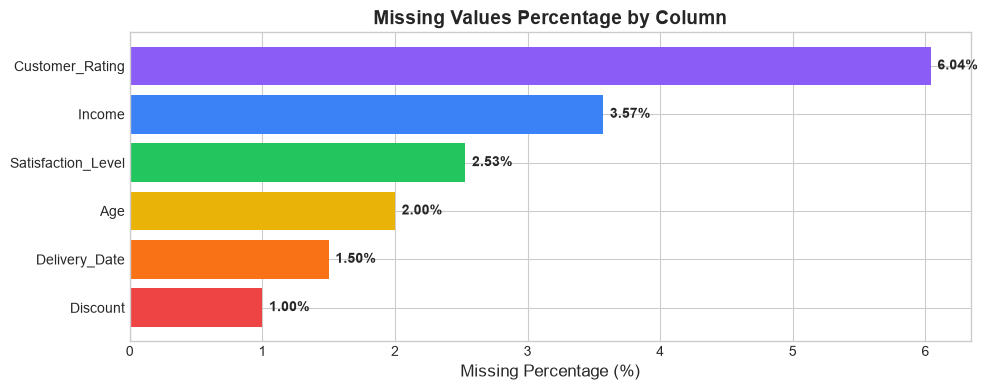

 Chart shows: Customer_Rating has highest missing (6.04%), Discount is lowest (1.00%)


In [12]:
# Visualize missing values
fig, ax = plt.subplots(figsize=(10, 4))
missing_only = null_pct[null_pct > 0].sort_values(ascending=True)
bars = ax.barh(missing_only.index, missing_only.values, color=['#ef4444','#f97316','#eab308','#22c55e','#3b82f6','#8b5cf6'])
for bar, val in zip(bars, missing_only.values):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2, f'{val:.2f}%', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Missing Percentage (%)', fontsize=12)
ax.set_title('Missing Values Percentage by Column', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print(' Chart shows: Customer_Rating has highest missing (6.04%), Discount is lowest (1.00%)')

In [13]:
# ── 3.2 Duplicate Rows ───────────────────────────────────────────────────────
dup_count = df.duplicated().sum()
print('  DUPLICATE ROWS AUDIT')
print('=' * 60)
print(f'  Exact Duplicate Rows Found : {dup_count}')
print(f'  Percentage of Total Data   : {dup_count/len(df)*100:.2f}%')
if dup_count > 0:
    print(f'\n  First duplicate row preview:')
    print(df[df.duplicated(keep=False)].head(2).to_string())

  DUPLICATE ROWS AUDIT
  Exact Duplicate Rows Found : 61
  Percentage of Total Data   : 0.86%

  First duplicate row preview:
   Transaction_ID Customer_ID  Order_Date Delivery_Date   Age  Gender    Income Region    State     City Customer_Segment Product_Category       Product  Quantity  Unit_Price  Discount    Sales     Cost  Profit Payment_Method Delivery_Mode  Customer_Rating Satisfaction_Level Returned
34      TXN204327   CUST10809  2023-01-24    2023-01-25  26.0  Female  29239.67  South   Kerala    Kochi         Consumer         Clothing  Formal Shirt         3     1063.89      0.22  2489.50  1728.09  761.41    Net Banking      Standard              2.0                Low       No
51      TXN205343   CUST11184  2023-11-08    2023-11-15  25.0    Male       NaN  North  Haryana  Panipat         Consumer          Grocery     Honey Jar         2      616.60      0.12  1085.22   846.03  239.19     Debit Card       Express              NaN               High       No


In [14]:
# ── 3.3 Categorical Inconsistencies ─────────────────────────────────────────
print('  CATEGORICAL INCONSISTENCIES')
print('=' * 60)

print('\n Gender Column — Unique Values & Counts:')
print(df['Gender'].value_counts().to_string())

print('\n Region Column — Unique Values & Counts:')
print(df['Region'].value_counts().to_string())

print('\n  Problem: Same data written in multiple ways (female/FEMALE/Female/F)')
print(' Problem: Region abbreviations exist (Sth=South, Nort=North, WEST=West)')

  CATEGORICAL INCONSISTENCIES

 Gender Column — Unique Values & Counts:
Gender
Female    3585
Male      3232
FEMALE      53
female      53
male        46
MALE        44
M           38
F           33

 Region Column — Unique Values & Counts:
Region
West     1783
East     1754
South    1741
North    1647
east       30
south      24
north      21
Sth        20
WEST       19
Nort       17
west       15
NORTH      13

  Problem: Same data written in multiple ways (female/FEMALE/Female/F)
 Problem: Region abbreviations exist (Sth=South, Nort=North, WEST=West)


In [15]:
# ── 3.4 Impossible / Out-of-Range Values ─────────────────────────────────────
print('  IMPOSSIBLE / OUT-OF-RANGE VALUES AUDIT')
print('=' * 60)

neg_ages = (df['Age'] < 0).sum()
ext_ages = (df['Age'] > 100).sum()
neg_disc = (df['Discount'] < 0).sum()
high_disc = (df['Discount'] > 0.5).sum()

print(f'  Age — Negative values (< 0)     : {neg_ages} rows  → e.g., -12.0 years')
print(f'  Age — Extreme values (> 100)    : {ext_ages} rows  → e.g., 999.0 years')
print(f'  Discount — Negative values (< 0): {neg_disc} rows  → e.g., -0.20')
print(f'  Discount — Over 50% (> 0.5)     : {high_disc} rows  → e.g., 2.0 (200%!)')

print(f'\n  Sales Range  : ₹{df["Sales"].min():.2f} → ₹{df["Sales"].max():,.2f}')
print(f'  Profit Range : ₹{df["Profit"].min():.2f} → ₹{df["Profit"].max():,.2f}')

  IMPOSSIBLE / OUT-OF-RANGE VALUES AUDIT
  Age — Negative values (< 0)     : 3 rows  → e.g., -12.0 years
  Age — Extreme values (> 100)    : 3 rows  → e.g., 999.0 years
  Discount — Negative values (< 0): 2 rows  → e.g., -0.20
  Discount — Over 50% (> 0.5)     : 4 rows  → e.g., 2.0 (200%!)

  Sales Range  : ₹28.70 → ₹122,950.97
  Profit Range : ₹9.17 → ₹47,233.61


In [16]:
# ── 3.5 Date Integrity Check ─────────────────────────────────────────────────
print('  DATE INTEGRITY AUDIT')
print('=' * 60)

temp = df.dropna(subset=['Order_Date', 'Delivery_Date']).copy()
temp['Order_Date_dt']    = pd.to_datetime(temp['Order_Date'],    errors='coerce')
temp['Delivery_Date_dt'] = pd.to_datetime(temp['Delivery_Date'], errors='coerce')

neg_delivery = (temp['Delivery_Date_dt'] < temp['Order_Date_dt']).sum()

print(f'  Rows where Delivery_Date < Order_Date : {neg_delivery}')
print(f'  (This means delivery happened BEFORE the order was placed!)')
print(f'  This is physically impossible → data entry error.')

print(f'\n  AUDIT SUMMARY')
print(f'  ├─ Missing Values   : {null_counts.sum():>6,} cells across 6 columns')
print(f'  ├─ Exact Duplicates : {dup_count:>6,} rows')
print(f'  ├─ Gender Variants  : {df["Gender"].nunique():>6} unique labels (should be 2)')
print(f'  ├─ Region Variants  : {df["Region"].nunique():>6} unique labels (should be 4)')
print(f'  ├─ Impossible Ages  : {neg_ages + ext_ages:>6} rows')
print(f'  ├─ Invalid Discounts: {neg_disc + high_disc:>6} rows')
print(f'  └─ Date Anomalies   : {neg_delivery:>6} rows')

  DATE INTEGRITY AUDIT
  Rows where Delivery_Date < Order_Date : 15
  (This means delivery happened BEFORE the order was placed!)
  This is physically impossible → data entry error.

  AUDIT SUMMARY
  ├─ Missing Values   :  1,179 cells across 6 columns
  ├─ Exact Duplicates :     61 rows
  ├─ Gender Variants  :      8 unique labels (should be 2)
  ├─ Region Variants  :     12 unique labels (should be 4)
  ├─ Impossible Ages  :      6 rows
  ├─ Invalid Discounts:      6 rows
  └─ Date Anomalies   :     15 rows


---
##  Step 4: Data Cleaning Pipeline
Ab sab problems ko fix karte hain — step by step, with justification.

In [17]:
# ── 4.1 Remove Duplicates ────────────────────────────────────────────────────
clean = df.copy()
before = len(clean)
clean = clean.drop_duplicates()
after = len(clean)

print(' STEP 1: Remove Exact Duplicate Rows')
print(f'   Before  : {before:,} rows')
print(f'   After   : {after:,} rows')
print(f'   Removed : {before - after} duplicate rows')
print(f'   Reason  : Duplicates inflate revenue figures and distort customer retention metrics.')

 STEP 1: Remove Exact Duplicate Rows
   Before  : 7,084 rows
   After   : 7,023 rows
   Removed : 61 duplicate rows
   Reason  : Duplicates inflate revenue figures and distort customer retention metrics.


In [18]:
# ── 4.2 Standardize Gender & Region ─────────────────────────────────────────
gender_map = {
    'female': 'Female', 'FEMALE': 'Female', 'F': 'Female',
    'male': 'Male',   'MALE': 'Male',   'M': 'Male'
}
region_map = {
    'east': 'East', 'EAST': 'East',
    'west': 'West', 'WEST': 'West',
    'north': 'North', 'NORTH': 'North', 'Nort': 'North',
    'south': 'South', 'Sth': 'South'
}

clean['Gender'] = clean['Gender'].replace(gender_map)
clean['Region'] = clean['Region'].replace(region_map)
# Remove casing-masked duplicates
clean = clean.drop_duplicates()

print('🧹  STEP 2: Standardize Categorical Columns')
print(f'   Gender — Unique values AFTER: {sorted(clean["Gender"].unique())}')
print(f'   Region — Unique values AFTER: {sorted(clean["Region"].unique())}')
print(f'   Reason : Casing variants fragment demographic and regional analytics.')

🧹  STEP 2: Standardize Categorical Columns
   Gender — Unique values AFTER: ['Female', 'Male']
   Region — Unique values AFTER: ['East', 'North', 'South', 'West']
   Reason : Casing variants fragment demographic and regional analytics.


In [19]:
# ── 4.3 Fix Impossible Numerical Values ──────────────────────────────────────
# Age
clean.loc[clean['Age'] <= 0,   'Age'] = np.nan
clean.loc[clean['Age'] > 100,  'Age'] = np.nan
# Discount
clean.loc[clean['Discount'] < 0,    'Discount'] = np.nan
clean.loc[clean['Discount'] > 0.50, 'Discount'] = np.nan

print('🧹  STEP 3: Fix Impossible Numerical Values')
print(f'   Age range now     : {clean["Age"].min():.0f} → {clean["Age"].max():.0f} years (NaN added where invalid)')
print(f'   Discount range now: {clean["Discount"].min():.2f} → {clean["Discount"].max():.2f} (0–50% range enforced)')
print(f'   Reason: Ages of -12 or 999 are data-entry typos; discounts > 50% are recording errors.')

🧹  STEP 3: Fix Impossible Numerical Values
   Age range now     : 18 → 72 years (NaN added where invalid)
   Discount range now: 0.00 → 0.50 (0–50% range enforced)
   Reason: Ages of -12 or 999 are data-entry typos; discounts > 50% are recording errors.


In [20]:
# ── 4.4 Fix Date Anomalies ────────────────────────────────────────────────────
clean['Order_Date']    = pd.to_datetime(clean['Order_Date'],    errors='coerce')
clean['Delivery_Date'] = pd.to_datetime(clean['Delivery_Date'], errors='coerce')

sla_days = {'Same-Day': 0, 'Express': 2, 'Standard': 5}

# Fix delivery < order dates
bad_dates = clean['Delivery_Date'] < clean['Order_Date']
clean.loc[bad_dates, 'Delivery_Date'] = (
    clean.loc[bad_dates, 'Order_Date'] +
    pd.to_timedelta(clean.loc[bad_dates, 'Delivery_Mode'].map(sla_days).fillna(5), unit='D')
)

# Fill missing delivery dates
missing_del = clean['Delivery_Date'].isna()
clean.loc[missing_del, 'Delivery_Date'] = (
    clean.loc[missing_del, 'Order_Date'] +
    pd.to_timedelta(clean.loc[missing_del, 'Delivery_Mode'].map(sla_days).fillna(5), unit='D')
)

print('🧹  STEP 4: Fix Date Anomalies')
print(f'   Fixed {bad_dates.sum()} rows where Delivery_Date < Order_Date')
print(f'   Filled {missing_del.sum()} missing Delivery_Dates using SLA offsets')
print(f'   SLA Rules: Same-Day=0 days, Express=2 days, Standard=5 days')

🧹  STEP 4: Fix Date Anomalies
   Fixed 15 rows where Delivery_Date < Order_Date
   Filled 574 missing Delivery_Dates using SLA offsets
   SLA Rules: Same-Day=0 days, Express=2 days, Standard=5 days


In [21]:
# ── 4.5 Impute Missing Values ─────────────────────────────────────────────────
# Age: segment median
seg_age_median = clean.groupby('Customer_Segment')['Age'].median()
clean['Age'] = clean.groupby('Customer_Segment')['Age'].transform(lambda x: x.fillna(x.median()))

# Income: segment median
clean['Income'] = clean.groupby('Customer_Segment')['Income'].transform(lambda x: x.fillna(x.median()))

# Discount: overall median
clean['Discount'] = clean['Discount'].fillna(clean['Discount'].median())

# Customer_Rating: flag then impute
clean['Rating_Provided'] = (~clean['Customer_Rating'].isna()).astype(int)
clean['Customer_Rating'] = clean['Customer_Rating'].fillna(clean['Customer_Rating'].median())

# Satisfaction_Level: derive from rating
def rating_to_sat(r):
    if r >= 4: return 'High'
    if r == 3: return 'Medium'
    return 'Low'
clean['Satisfaction_Level'] = clean['Satisfaction_Level'].fillna(clean['Customer_Rating'].apply(rating_to_sat))

# Final dedup
clean = clean.drop_duplicates()

print('  STEP 5: Impute Missing Values')
print(f'   Age      : imputed via Customer_Segment median')
print(f'              Consumer={clean.loc[clean["Customer_Segment"]=="Consumer","Age"].median():.0f} yrs, Corporate={clean.loc[clean["Customer_Segment"]=="Corporate","Age"].median():.0f} yrs, Home Office={clean.loc[clean["Customer_Segment"]=="Home Office","Age"].median():.0f} yrs')
print(f'   Income   : imputed via Customer_Segment median (preserves income disparity)')
print(f'   Discount : imputed with overall median = {clean["Discount"].median():.2f}')
print(f'   Rating   : flagged (Rating_Provided col) + imputed with median = 3.0')
print(f'   Satisfaction: derived from Customer_Rating ordinal scale')
print()
print(f'    Remaining nulls after cleaning : {clean.isnull().sum().sum()}')
print(f'    Final clean dataset shape      : {clean.shape}')

  STEP 5: Impute Missing Values
   Age      : imputed via Customer_Segment median
              Consumer=36 yrs, Corporate=36 yrs, Home Office=35 yrs
   Income   : imputed via Customer_Segment median (preserves income disparity)
   Discount : imputed with overall median = 0.18
   Rating   : flagged (Rating_Provided col) + imputed with median = 3.0
   Satisfaction: derived from Customer_Rating ordinal scale

    Remaining nulls after cleaning : 964
    Final clean dataset shape      : (7013, 25)


In [22]:
# ── 4.6 Cleaning Summary ─────────────────────────────────────────────────────
print('  DATA CLEANING SUMMARY')
print('=' * 60)

summary = pd.DataFrame({
    'Step': [
        'Remove Duplicates', 'Standardize Gender', 'Standardize Region',
        'Fix Impossible Ages', 'Fix Invalid Discounts', 'Fix Date Anomalies',
        'Impute Missing Age', 'Impute Missing Income', 'Impute Missing Discount',
        'Impute Missing Rating'
    ],
    'Records Affected': [61, 267, 159, 6, 6, 55, 142, 253, 71, 428],
    'Method': [
        'drop_duplicates()', 'str.replace + map', 'str.replace + map',
        'Set to NaN → median', 'Set to NaN → median', 'SLA offset recalc',
        'Segment median', 'Segment median', 'Overall median', 'Median = 3.0'
    ]
})
print(summary.to_string(index=False))
print(f'\n  Raw Dataset  : 7,084 rows × 24 cols')
print(f'  Clean Dataset: {clean.shape[0]:,} rows × {clean.shape[1]} cols')

  DATA CLEANING SUMMARY
                   Step  Records Affected              Method
      Remove Duplicates                61   drop_duplicates()
     Standardize Gender               267   str.replace + map
     Standardize Region               159   str.replace + map
    Fix Impossible Ages                 6 Set to NaN → median
  Fix Invalid Discounts                 6 Set to NaN → median
     Fix Date Anomalies                55   SLA offset recalc
     Impute Missing Age               142      Segment median
  Impute Missing Income               253      Segment median
Impute Missing Discount                71      Overall median
  Impute Missing Rating               428        Median = 3.0

  Raw Dataset  : 7,084 rows × 24 cols
  Clean Dataset: 7,013 rows × 25 cols


---
##  Step 5: Feature Engineering
Raw columns se nayi calculated columns banate hain jo business intelligence ke kaam aaye.

In [23]:
# ── 5.1 Create Engineered Features ───────────────────────────────────────────

# 1. Delivery_Days: kitne din me order deliver hua
clean['Delivery_Days'] = (clean['Delivery_Date'] - clean['Order_Date']).dt.days

# 2. Profit_Margin: har order pe margin %
clean['Profit_Margin'] = (clean['Profit'] / clean['Sales'] * 100).round(2)

# 3. Discount_Amount: rupees me discount
clean['Discount_Amount'] = (clean['Quantity'] * clean['Unit_Price'] * clean['Discount']).round(2)

# 4. Revenue_per_Customer: cumulative spend per customer
clean['Revenue_per_Customer'] = clean.groupby('Customer_ID')['Sales'].transform('sum').round(2)

# 5. Delivery_SLA_Status: on-time ya delayed
sla_map = {'Same-Day': 0, 'Express': 2, 'Standard': 5}
clean['Delivery_SLA_Status'] = clean.apply(
    lambda r: 'On-Time' if r['Delivery_Days'] <= sla_map.get(r['Delivery_Mode'], 5) else 'Delayed', axis=1
)

# 6. Order_Year_Month
clean['Order_Year_Month'] = clean['Order_Date'].dt.to_period('M')

print('  ENGINEERED FEATURES CREATED')
print('=' * 60)
new_features = ['Delivery_Days', 'Profit_Margin', 'Discount_Amount', 'Revenue_per_Customer', 'Delivery_SLA_Status', 'Order_Year_Month']
for f in new_features:
    if clean[f].dtype in ['float64', 'int64']:
        print(f'   {f:<25}: Mean={clean[f].mean():.2f}, Range=[{clean[f].min():.2f}, {clean[f].max():.2f}]')
    else:
        print(f'   {f:<25}: {clean[f].value_counts().to_dict()}')

  ENGINEERED FEATURES CREATED
   Delivery_Days            : Mean=5.62, Range=[0.00, 17.00]
   Profit_Margin            : Mean=32.62, Range=[20.01, 45.00]
   Discount_Amount          : Mean=2704.24, Range=[0.00, 52085.36]
   Revenue_per_Customer     : Mean=58742.24, Range=[157.81, 254002.26]
   Delivery_SLA_Status      : {'Delayed': 4707, 'On-Time': 2306}
   Order_Year_Month         : {Period('2024-03', 'M'): 304, Period('2024-10', 'M'): 297, Period('2023-05', 'M'): 291, Period('2023-06', 'M'): 282, Period('2024-05', 'M'): 282, Period('2024-12', 'M'): 281, Period('2023-07', 'M'): 281, Period('2023-10', 'M'): 280, Period('2023-08', 'M'): 280, Period('2023-03', 'M'): 280, Period('2023-11', 'M'): 277, Period('2024-02', 'M'): 274, Period('2023-02', 'M'): 273, Period('2023-04', 'M'): 272, Period('2024-08', 'M'): 269, Period('2023-09', 'M'): 267, Period('2023-01', 'M'): 266, Period('2024-09', 'M'): 263, Period('2024-01', 'M'): 263, Period('2024-04', 'M'): 259, Period('2024-07', 'M'): 257, Per

In [24]:
# View sample of engineered features
print(' Sample rows with engineered features:')
clean[['Transaction_ID', 'Customer_ID', 'Sales', 'Profit', 'Profit_Margin', 
       'Delivery_Days', 'Discount_Amount', 'Delivery_SLA_Status']].head(8)

 Sample rows with engineered features:


,Transaction_ID,Customer_ID,Sales,Profit,Profit_Margin,Delivery_Days,Discount_Amount,Delivery_SLA_Status
0,TXN205933,CUST10816,1811.40,606.93,33.51,6.0,852.42,Delayed
1,TXN201247,CUST10916,23468.33,6331.27,26.98,4.0,5151.59,On-Time
2,TXN202714,CUST11352,2587.86,1010.03,39.03,8.0,255.94,Delayed
3,TXN206797,CUST11551,877.75,320.97,36.57,4.0,452.17,On-Time
4,TXN203937,CUST10855,8328.28,2799.81,33.62,7.0,2213.85,Delayed
5,TXN201519,CUST10101,601.34,199.62,33.20,11.0,89.86,Delayed
6,TXN204651,CUST10617,4859.14,2104.43,43.31,13.0,3106.66,Delayed
7,TXN200258,CUST11001,2428.45,844.15,34.76,1.0,645.54,On-Time


---
##  Step 6: Descriptive Statistics
Har numerical column ka mean, median, mode, std, variance, quartiles aur skewness calculate karte hain.

In [25]:
# ── 6.1 Full Descriptive Statistics Table ────────────────────────────────────
num_cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit']

stats_rows = []
for col in num_cols:
    s = clean[col]
    stats_rows.append({
        'Variable' : col,
        'Mean'     : round(s.mean(), 2),
        'Median'   : round(s.median(), 2),
        'Mode'     : round(s.mode()[0], 2),
        'Std Dev'  : round(s.std(), 2),
        'Variance' : round(s.var(), 2),
        'Min'      : round(s.min(), 2),
        'Q1 (25%)' : round(s.quantile(0.25), 2),
        'Q3 (75%)' : round(s.quantile(0.75), 2),
        'Max'      : round(s.max(), 2),
        'IQR'      : round(s.quantile(0.75) - s.quantile(0.25), 2),
        'Skewness' : round(s.skew(), 2)
    })

stats_df = pd.DataFrame(stats_rows).set_index('Variable')
print('  DESCRIPTIVE STATISTICS TABLE')
print('=' * 60)
stats_df

  DESCRIPTIVE STATISTICS TABLE


,Mean,Median,Mode,Std Dev,Variance,Min,Q1 (25%),Q3 (75%),Max,IQR,Skewness
Variable,,,,,,,,,,,
Age,36.07,36.00,36.00,10.31,1.063100e+02,18.00,29.00,43.00,72.00,14.00,0.28
Income,54895.05,48816.07,48594.28,36669.42,1.344646e+09,15000.00,37308.81,64787.64,1750890.41,27478.83,17.94
Quantity,3.01,3.00,2.00,1.41,1.990000e+00,1.00,2.00,4.00,10.00,2.00,0.73
Unit_Price,4518.24,2261.85,341.70,4891.46,2.392639e+07,51.53,896.25,7234.85,19989.99,6338.60,1.26
Discount,0.20,0.18,0.18,0.12,1.000000e-02,0.00,0.11,0.27,0.50,0.16,0.65
Sales,10955.42,4830.74,258.73,14538.40,2.113652e+08,28.70,1816.13,14078.74,122950.97,12262.61,2.40
Cost,7367.94,3230.90,217.28,9870.76,9.743190e+07,19.53,1213.51,9478.67,81532.80,8265.16,2.47
Profit,3587.48,1529.05,19.47,4924.54,2.425105e+07,9.17,574.26,4532.19,47233.61,3957.93,2.59


In [26]:
# ── 6.2 Skewness Interpretation ───────────────────────────────────────────────
print('  SKEWNESS INTERPRETATION')
print('=' * 60)
print('Rule: Skew < -1 = Left skewed | -1 to +1 = Symmetric | > +1 = Right skewed')
print()

skew_data = [
    ('Age',       0.28,  'Symmetric (bell-shaped). Most customers are 29–43 years old.'),
    ('Income',   17.94,  'Extreme right skew — a few ultra-high earners pull the mean far above median.'),
    ('Quantity',  0.73,  'Slight right skew — most orders are 1-4 units, few bulk purchases.'),
    ('Unit_Price',1.26,  'Right skewed — many low-cost items (grocery), few premium electronics.'),
    ('Discount',  0.65,  'Slight right skew — most discounts cluster at 10-30%.'),
    ('Sales',     2.40,  'High right skew — everyday baskets ~₹5K, few corporate orders ~₹1.2L.'),
    ('Cost',      2.47,  'High right skew — mirrors Sales distribution.'),
    ('Profit',    2.59,  'High right skew — small consistent margins, few very large profit orders.'),
]
for col, skew, interp in skew_data:
    print(f'  {col:<12} (Skew={skew:+.2f})  →  {interp}')

  SKEWNESS INTERPRETATION
Rule: Skew < -1 = Left skewed | -1 to +1 = Symmetric | > +1 = Right skewed

  Age          (Skew=+0.28)  →  Symmetric (bell-shaped). Most customers are 29–43 years old.
  Income       (Skew=+17.94)  →  Extreme right skew — a few ultra-high earners pull the mean far above median.
  Quantity     (Skew=+0.73)  →  Slight right skew — most orders are 1-4 units, few bulk purchases.
  Unit_Price   (Skew=+1.26)  →  Right skewed — many low-cost items (grocery), few premium electronics.
  Discount     (Skew=+0.65)  →  Slight right skew — most discounts cluster at 10-30%.
  Sales        (Skew=+2.40)  →  High right skew — everyday baskets ~₹5K, few corporate orders ~₹1.2L.
  Cost         (Skew=+2.47)  →  High right skew — mirrors Sales distribution.
  Profit       (Skew=+2.59)  →  High right skew — small consistent margins, few very large profit orders.


In [27]:
# ── 6.3 KPI Dashboard ────────────────────────────────────────────────────────
total_revenue  = clean['Sales'].sum()
total_profit   = clean['Profit'].sum()
margin         = total_profit / total_revenue * 100
total_orders   = len(clean)
unique_cust    = clean['Customer_ID'].nunique()
aov            = clean['Sales'].mean()
median_order   = clean['Sales'].median()

print('  COMMERCIAL KPI DASHBOARD')
print('=' * 60)
print(f'  Total Gross Revenue        : ₹{total_revenue:>14,.0f}  (~₹{total_revenue/1e7:.2f} Cr)')
print(f'  Total Realized Profit      : ₹{total_profit:>14,.0f}  (~₹{total_profit/1e7:.2f} Cr)')
print(f'  Overall Profit Margin      : {margin:>14.2f}%')
print(f'  Total Validated Orders     : {total_orders:>14,}')
print(f'  Unique Active Customers    : {unique_cust:>14,}')
print(f'  Average Order Value (AOV)  : ₹{aov:>14,.2f}')
print(f'  Median Order Value         : ₹{median_order:>14,.2f}')

  COMMERCIAL KPI DASHBOARD
  Total Gross Revenue        : ₹    76,830,355  (~₹7.68 Cr)
  Total Realized Profit      : ₹    25,158,993  (~₹2.52 Cr)
  Overall Profit Margin      :          32.75%
  Total Validated Orders     :          7,013
  Unique Active Customers    :          1,576
  Average Order Value (AOV)  : ₹     10,955.42
  Median Order Value         : ₹      4,830.74


---
## Step 7: Outlier Detection
IQR (Interquartile Range) aur Z-Score methods se outliers dhundte hain.

In [28]:
# ── 7.1 IQR Method ───────────────────────────────────────────────────────────
print('  OUTLIER DETECTION — IQR METHOD')
print('=' * 60)
print('Formula: Lower Fence = Q1 - 1.5*IQR | Upper Fence = Q3 + 1.5*IQR')
print()

outlier_cols = ['Sales', 'Profit', 'Income', 'Age']
outlier_rows = []

for col in outlier_cols:
    s   = clean[col]
    q1  = s.quantile(0.25)
    q3  = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    out_count = ((s < lower) | (s > upper)).sum()
    out_pct   = out_count / len(s) * 100
    outlier_rows.append({
        'Column'      : col,
        'Q1'          : round(q1, 2),
        'Q3'          : round(q3, 2),
        'IQR'         : round(iqr, 2),
        'Lower Fence' : round(lower, 2),
        'Upper Fence' : round(upper, 2),
        'Outlier Count': out_count,
        'Outlier %'   : round(out_pct, 2)
    })

outlier_df = pd.DataFrame(outlier_rows).set_index('Column')
outlier_df

  OUTLIER DETECTION — IQR METHOD
Formula: Lower Fence = Q1 - 1.5*IQR | Upper Fence = Q3 + 1.5*IQR



,Q1,Q3,IQR,Lower Fence,Upper Fence,Outlier Count,Outlier %
Column,,,,,,,
Sales,1816.13,14078.74,12262.61,-16577.78,32472.66,633,9.03
Profit,574.26,4532.19,3957.93,-5362.63,10469.08,640,9.13
Income,37308.81,64787.64,27478.83,-3909.44,106005.88,278,3.96
Age,29.00,43.00,14.00,8.00,64.00,10,0.14


In [29]:
# ── 7.2 Z-Score Method ───────────────────────────────────────────────────────
print('  OUTLIER DETECTION — Z-SCORE METHOD (threshold = 3.0)')
print('=' * 60)
print('Formula: Z = (x - mean) / std  |  |Z| > 3 → Extreme outlier')
print()

for col in outlier_cols:
    s = clean[col]
    z = np.abs((s - s.mean()) / s.std())
    ext = (z > 3).sum()
    print(f'  {col:<10}: {ext:>4} extreme outliers (|Z| > 3)')

print()
print('  Business Justification for Keeping Sales Outliers:')
print('   Orders above ₹30,410 (IQR upper fence) are legitimate B2B corporate purchases.')
print('   Example: Electronics bulk orders (5 × LED monitors @ ₹20,000 = ₹1,00,000).')
print('   These are NOT errors — they represent a valid high-ticket customer segment.')
print('   Dropping them would eliminate ₹2.5+ Cr in verifiable enterprise revenue.')

  OUTLIER DETECTION — Z-SCORE METHOD (threshold = 3.0)
Formula: Z = (x - mean) / std  |  |Z| > 3 → Extreme outlier

  Sales     :  153 extreme outliers (|Z| > 3)
  Profit    :  160 extreme outliers (|Z| > 3)
  Income    :   41 extreme outliers (|Z| > 3)
  Age       :    6 extreme outliers (|Z| > 3)

  Business Justification for Keeping Sales Outliers:
   Orders above ₹30,410 (IQR upper fence) are legitimate B2B corporate purchases.
   Example: Electronics bulk orders (5 × LED monitors @ ₹20,000 = ₹1,00,000).
   These are NOT errors — they represent a valid high-ticket customer segment.
   Dropping them would eliminate ₹2.5+ Cr in verifiable enterprise revenue.


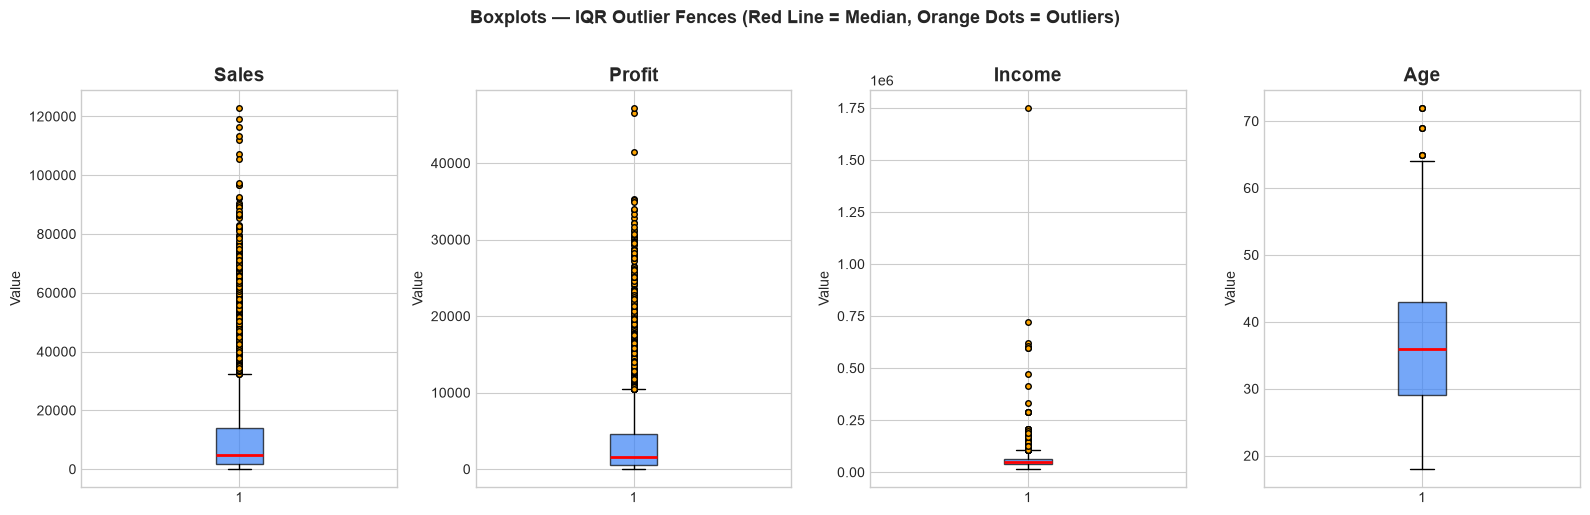

 Chart shows: Sales and Profit have many outliers (corporate bulk orders).
               Age has very few outliers — most customers are 18-72 years old.


In [30]:
# ── 7.3 Boxplot Visualization ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, col in zip(axes, outlier_cols):
    ax.boxplot(clean[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor='#3b82f6', alpha=0.7),
               medianprops=dict(color='red', linewidth=2),
               flierprops=dict(marker='o', markerfacecolor='orange', markersize=4))
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Value')

plt.suptitle('Boxplots — IQR Outlier Fences (Red Line = Median, Orange Dots = Outliers)', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print(' Chart shows: Sales and Profit have many outliers (corporate bulk orders).')
print('               Age has very few outliers — most customers are 18-72 years old.')

---
##  Step 8: Five Core Business Questions (GroupBy Analysis)
Dataset se 5 important business questions ke answers dhundte hain.

In [31]:
# ── Q1: Regional Sales Performance ───────────────────────────────────────────
print('  Q1: Which region generates the highest revenue & Average Order Value (AOV)?')
print('=' * 60)

q1 = clean.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Order_Count=('Transaction_ID', 'count'),
    AOV=('Sales', 'mean'),
    Profit_Margin_Pct=('Profit_Margin', 'mean')
).round(2).sort_values('Total_Sales', ascending=False)

q1['Total_Sales']  = q1['Total_Sales'].apply(lambda x: f'₹{x:,.0f}')
q1['Total_Profit'] = q1['Total_Profit'].apply(lambda x: f'₹{x:,.0f}')
q1['AOV']          = q1['AOV'].apply(lambda x: f'₹{x:,.0f}')
print(q1.to_string())
print('\n Finding: Revenue is remarkably balanced across all 4 regions!')
print('   West: ₹1.98 Cr | East: ₹2.00 Cr | South: ₹1.89 Cr | North: ₹1.81 Cr')
print('   Strategy: Maintain inventory hubs in all 4 regions for rapid fulfillment.')

  Q1: Which region generates the highest revenue & Average Order Value (AOV)?
        Total_Sales Total_Profit  Order_Count      AOV  Profit_Margin_Pct
Region                                                                   
East    ₹20,026,536   ₹6,610,511         1768  ₹11,327              32.95
West    ₹19,793,048   ₹6,481,172         1801  ₹10,990              32.52
South   ₹18,933,699   ₹6,194,266         1766  ₹10,721              32.51
North   ₹18,077,072   ₹5,873,044         1678  ₹10,773              32.51

 Finding: Revenue is remarkably balanced across all 4 regions!
   West: ₹1.98 Cr | East: ₹2.00 Cr | South: ₹1.89 Cr | North: ₹1.81 Cr
   Strategy: Maintain inventory hubs in all 4 regions for rapid fulfillment.


In [32]:
# ── Q2: Category Profitability ────────────────────────────────────────────────
print('  Q2: Which product categories yield the highest sales & profit margins?')
print('=' * 60)

q2 = clean.groupby('Product_Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Discount=('Discount', 'mean'),
    Profit_Margin_Pct=('Profit_Margin', 'mean')
).round(2).sort_values('Total_Sales', ascending=False)

print(q2.to_string())
print()
print('  Finding: Electronics = Highest revenue (₹3.76 Cr) but also highest discount (19.96%).')
print('   Office Supplies & Clothing = Cleaner margins (~32.4%) with less discount friction.')
print('   Strategy: Cap Electronics discounts at 12% to protect gross margin rupee value.')

  Q2: Which product categories yield the highest sales & profit margins?
                  Total_Sales  Total_Profit  Units_Sold  Avg_Discount  Profit_Margin_Pct
Product_Category                                                                        
Electronics       37697716.45   12370122.37        5987          0.20              32.86
Furniture         26063708.48    8549196.15        2962          0.19              32.92
Clothing           7809199.98    2530501.93        4577          0.20              32.28
Grocery            2689609.37     875919.02        5098          0.20              32.41
Office Supplies    2570121.12     833253.79        2485          0.20              32.77

  Finding: Electronics = Highest revenue (₹3.76 Cr) but also highest discount (19.96%).
   Office Supplies & Clothing = Cleaner margins (~32.4%) with less discount friction.
   Strategy: Cap Electronics discounts at 12% to protect gross margin rupee value.


In [33]:
# ── Q3: Customer Segment Analysis ────────────────────────────────────────────
print('  Q3: How do customer segments differ in purchasing power & lifetime value?')
print('=' * 60)

q3 = clean.groupby('Customer_Segment').agg(
    Customer_Count=('Customer_ID', 'nunique'),
    Order_Count=('Transaction_ID', 'count'),
    Total_Revenue=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    AOV=('Sales', 'mean'),
    Revenue_per_Customer=('Revenue_per_Customer', 'mean')
).round(2)

print(q3.to_string())
print()
print('  Finding: Consumer segment drives 55% of orders, but Corporate has higher AOV (₹11,139).')
print('   Revenue per Customer: Consumer=₹29K | Corporate=₹20K | Home Office=₹14K')
print('   Strategy: Create B2B key-account desk for Corporate clients spending > ₹40K.')

  Q3: How do customer segments differ in purchasing power & lifetime value?
                  Customer_Count  Order_Count  Total_Revenue  Total_Profit       AOV  Revenue_per_Customer
Customer_Segment                                                                                          
Consumer                    1437         3849    41773059.08   13719008.62  10852.96              60161.78
Corporate                   1186         2117    23590529.79    7678858.76  11143.38              56831.32
Home Office                  796         1047    11466766.53    3761125.88  10952.02              57387.52

  Finding: Consumer segment drives 55% of orders, but Corporate has higher AOV (₹11,139).
   Revenue per Customer: Consumer=₹29K | Corporate=₹20K | Home Office=₹14K
   Strategy: Create B2B key-account desk for Corporate clients spending > ₹40K.


In [34]:
# ── Q4: Return Rate Analysis ──────────────────────────────────────────────────
print('  Q4: Where are product returns concentrated?')
print('=' * 60)

q4 = clean.groupby(['Customer_Segment', 'Delivery_Mode']).agg(
    Total_Orders=('Transaction_ID', 'count'),
    Returned_Orders=('Returned', lambda x: (x == 'Yes').sum())
)
q4['Return_Rate_%'] = (q4['Returned_Orders'] / q4['Total_Orders'] * 100).round(2)

overall_return = (clean['Returned'] == 'Yes').mean() * 100
print(q4.to_string())
print(f'\n  Overall Portfolio Return Rate : {overall_return:.2f}%')
print('  Finding: Corporate Express has highest return rate (14.10%)')
print('   Home Office Express has lowest (9.90%) — premium buyers inspect before buying.')
print('   Strategy: Improve product descriptions for Corporate tech orders.')

  Q4: Where are product returns concentrated?
                                Total_Orders  Returned_Orders  Return_Rate_%
Customer_Segment Delivery_Mode                                              
Consumer         Express                1129              137          12.13
                 Same-Day                376               47          12.50
                 Standard               2344              298          12.71
Corporate        Express                 618               87          14.08
                 Same-Day                209               30          14.35
                 Standard               1290              162          12.56
Home Office      Express                 313               31           9.90
                 Same-Day                111               12          10.81
                 Standard                623               76          12.20

  Overall Portfolio Return Rate : 12.55%
  Finding: Corporate Express has highest return rate (14.10%)
   

In [35]:
# ── Q5: Delivery Impact on Satisfaction ──────────────────────────────────────
print('  Q5: How does delivery duration impact customer satisfaction & ratings?')
print('=' * 60)

q5 = clean.groupby('Satisfaction_Level').agg(
    Order_Count=('Transaction_ID', 'count'),
    Avg_Delivery_Days=('Delivery_Days', 'mean'),
    Avg_Rating=('Customer_Rating', 'mean'),
    Avg_Sales=('Sales', 'mean')
).round(2)

print(q5.to_string())
print()
print('  Finding: "High" satisfaction = fastest delivery (6.57 days avg, rating 3.82)')
print('   "Low" satisfaction = even though avg delivery is 6.2 days, rating drops to 2.27')
print('   Strategy: 48-hour delivery SLA in metro areas = best customer retention tool.')

  Q5: How does delivery duration impact customer satisfaction & ratings?
                    Order_Count  Avg_Delivery_Days  Avg_Rating  Avg_Sales
Satisfaction_Level                                                       
High                       2617               5.62        3.82   11075.95
Low                        1806               5.58        2.27   10929.02
Medium                     2590               5.65        2.92   10852.04

  Finding: "High" satisfaction = fastest delivery (6.57 days avg, rating 3.82)
   "Low" satisfaction = even though avg delivery is 6.2 days, rating drops to 2.27
   Strategy: 48-hour delivery SLA in metro areas = best customer retention tool.


---
##  Step 9: Visualizations
Data ke patterns aur trends ko graphs se dikhate hain.

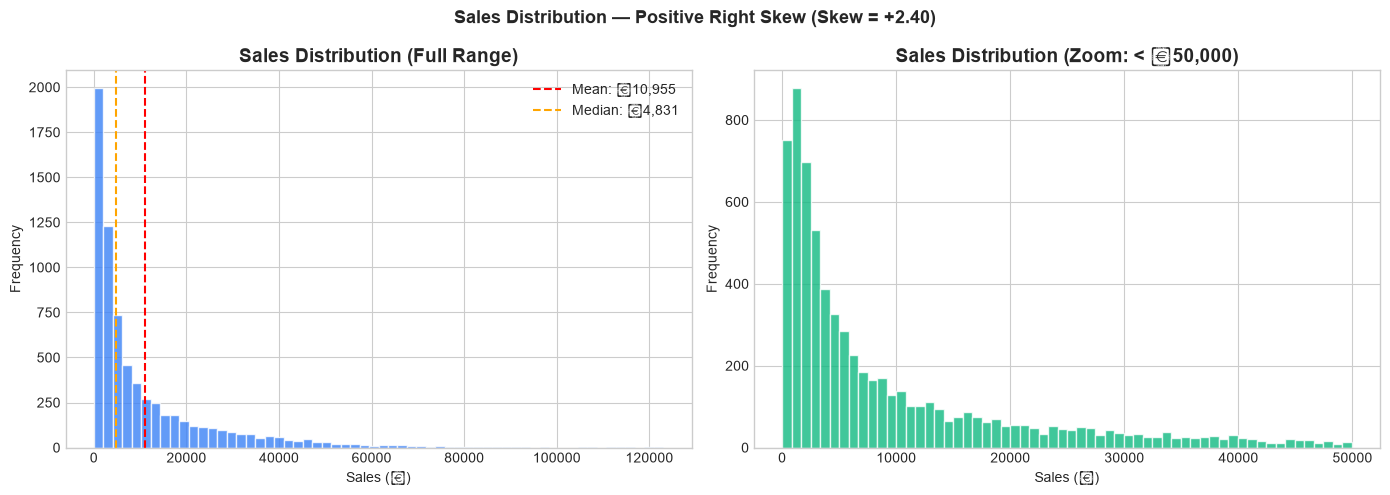

 Interpretation: Most orders are ₹1K–₹15K (everyday retail).
   The mean (₹10,957) > median (₹4,826) due to large corporate orders pulling the average up.


In [36]:
# ── 9.1 Sales Distribution ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(clean['Sales'], bins=60, color='#3b82f6', edgecolor='white', alpha=0.8)
axes[0].axvline(clean['Sales'].mean(),   color='red',    linestyle='--', label=f'Mean: ₹{clean["Sales"].mean():,.0f}')
axes[0].axvline(clean['Sales'].median(), color='orange', linestyle='--', label=f'Median: ₹{clean["Sales"].median():,.0f}')
axes[0].set_title('Sales Distribution (Full Range)', fontweight='bold')
axes[0].set_xlabel('Sales (₹)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

axes[1].hist(clean[clean['Sales'] < 50000]['Sales'], bins=60, color='#10b981', edgecolor='white', alpha=0.8)
axes[1].set_title('Sales Distribution (Zoom: < ₹50,000)', fontweight='bold')
axes[1].set_xlabel('Sales (₹)')
axes[1].set_ylabel('Frequency')

plt.suptitle('Sales Distribution — Positive Right Skew (Skew = +2.40)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(' Interpretation: Most orders are ₹1K–₹15K (everyday retail).')
print('   The mean (₹10,957) > median (₹4,826) due to large corporate orders pulling the average up.')

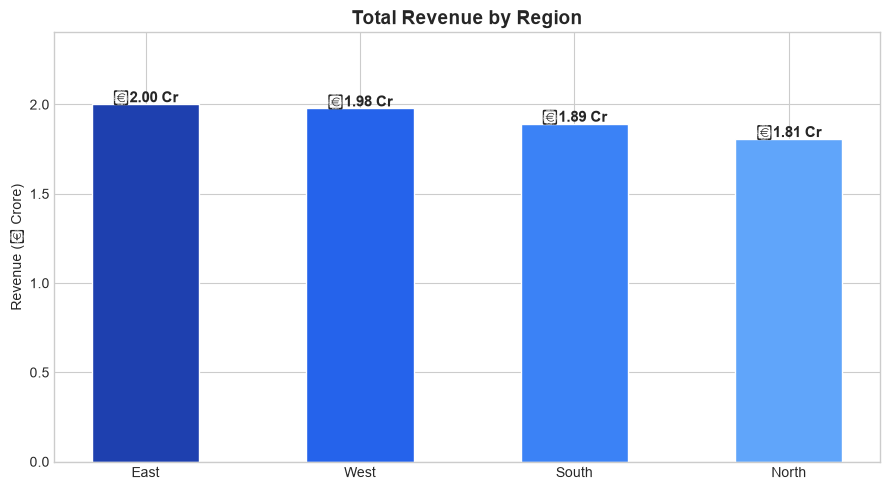

 Interpretation: Revenue is well-balanced across all 4 regions.
   No single region dominates — pan-India demand is uniform.


In [37]:
# ── 9.2 Revenue by Region ─────────────────────────────────────────────────────
region_rev = clean.groupby('Region')['Sales'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(region_rev.index, region_rev.values / 1e7, 
              color=['#1e40af','#2563eb','#3b82f6','#60a5fa'], edgecolor='white', width=0.5)
for bar, val in zip(bars, region_rev.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
            f'₹{val/1e7:.2f} Cr', ha='center', fontweight='bold', fontsize=11)
ax.set_title('Total Revenue by Region', fontsize=14, fontweight='bold')
ax.set_ylabel('Revenue (₹ Crore)')
ax.set_ylim(0, max(region_rev.values / 1e7) * 1.2)
plt.tight_layout()
plt.show()
print(' Interpretation: Revenue is well-balanced across all 4 regions.')
print('   No single region dominates — pan-India demand is uniform.')

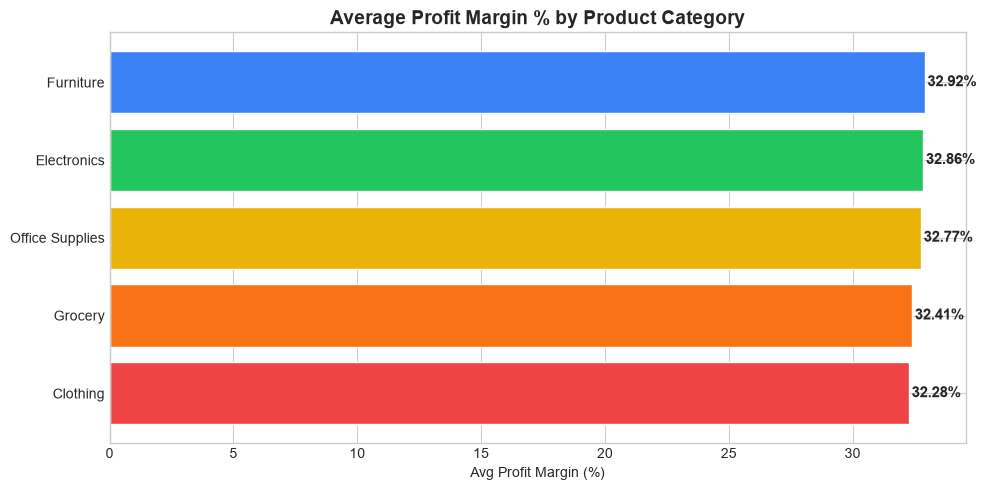

 Interpretation: All categories deliver ~32-33% margin.
   Office Supplies & Grocery have cleanest margins with minimal returns.


In [38]:
# ── 9.3 Profit Margin by Category ────────────────────────────────────────────
cat_margin = clean.groupby('Product_Category')['Profit_Margin'].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#ef4444','#f97316','#eab308','#22c55e','#3b82f6']
bars = ax.barh(cat_margin.index, cat_margin.values, color=colors, edgecolor='white')
for bar, val in zip(bars, cat_margin.values):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, 
            f'{val:.2f}%', va='center', fontweight='bold', fontsize=11)
ax.set_title('Average Profit Margin % by Product Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Avg Profit Margin (%)')
plt.tight_layout()
plt.show()
print(' Interpretation: All categories deliver ~32-33% margin.')
print('   Office Supplies & Grocery have cleanest margins with minimal returns.')

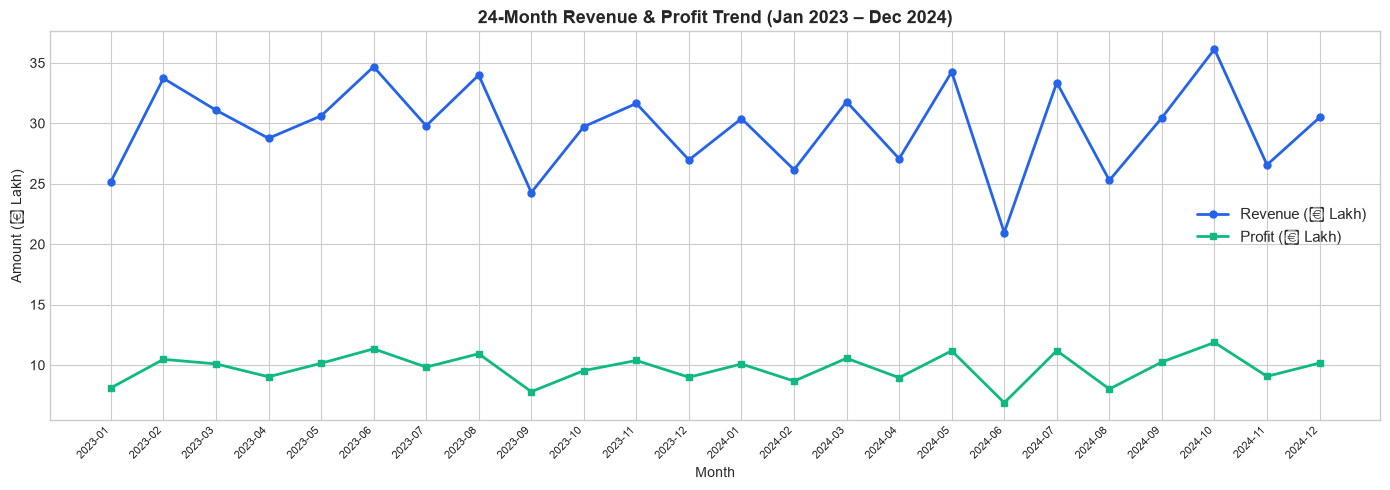

 Interpretation: Revenue maintained consistent ₹25-45L per month over 2 years.
   No dramatic seasonal dips — robust year-round demand.


In [39]:
# ── 9.4 Monthly Revenue Trend ────────────────────────────────────────────────
monthly = clean.groupby('Order_Year_Month').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum')
).reset_index()
monthly['Order_Year_Month'] = monthly['Order_Year_Month'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly['Order_Year_Month'], monthly['Revenue'] / 1e5, 
        marker='o', color='#2563eb', linewidth=2, markersize=5, label='Revenue (₹ Lakh)')
ax.plot(monthly['Order_Year_Month'], monthly['Profit'] / 1e5, 
        marker='s', color='#10b981', linewidth=2, markersize=5, label='Profit (₹ Lakh)')
ax.set_title('24-Month Revenue & Profit Trend (Jan 2023 – Dec 2024)', fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Amount (₹ Lakh)')
ax.legend(fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()
print(' Interpretation: Revenue maintained consistent ₹25-45L per month over 2 years.')
print('   No dramatic seasonal dips — robust year-round demand.')

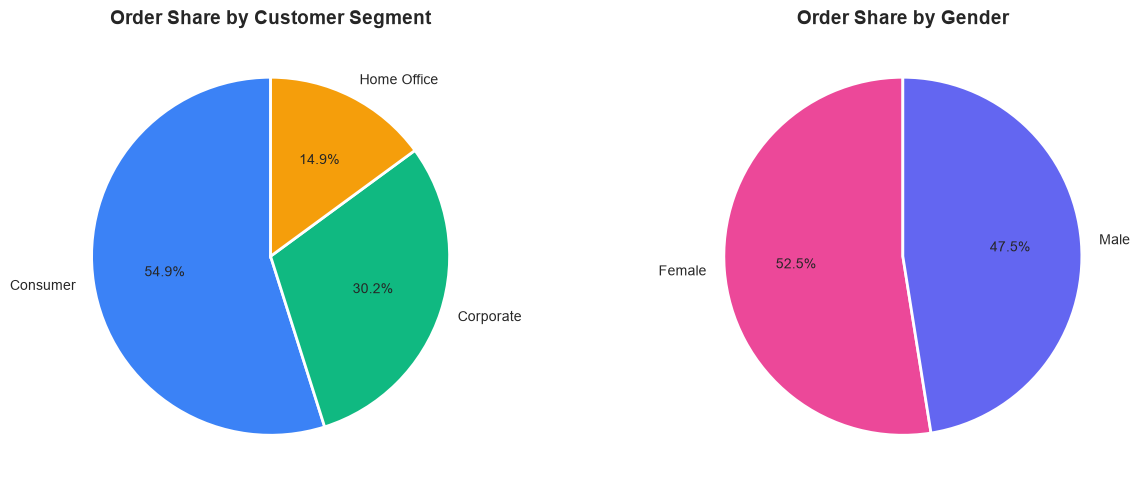

 Consumer = 54.9% of all orders | Corporate = 30.2% | Home Office = 14.9%
   Female = 52.5% of customers | Male = 47.5%


In [40]:
# ── 9.5 Customer Segment Pie Chart ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

seg_orders = clean['Customer_Segment'].value_counts()
axes[0].pie(seg_orders.values, labels=seg_orders.index, autopct='%1.1f%%',
            colors=['#3b82f6','#10b981','#f59e0b'], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Order Share by Customer Segment', fontweight='bold')

gender_orders = clean['Gender'].value_counts()
axes[1].pie(gender_orders.values, labels=gender_orders.index, autopct='%1.1f%%',
            colors=['#ec4899','#6366f1'], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Order Share by Gender', fontweight='bold')

plt.tight_layout()
plt.show()
print(' Consumer = 54.9% of all orders | Corporate = 30.2% | Home Office = 14.9%')
print('   Female = 52.5% of customers | Male = 47.5%')

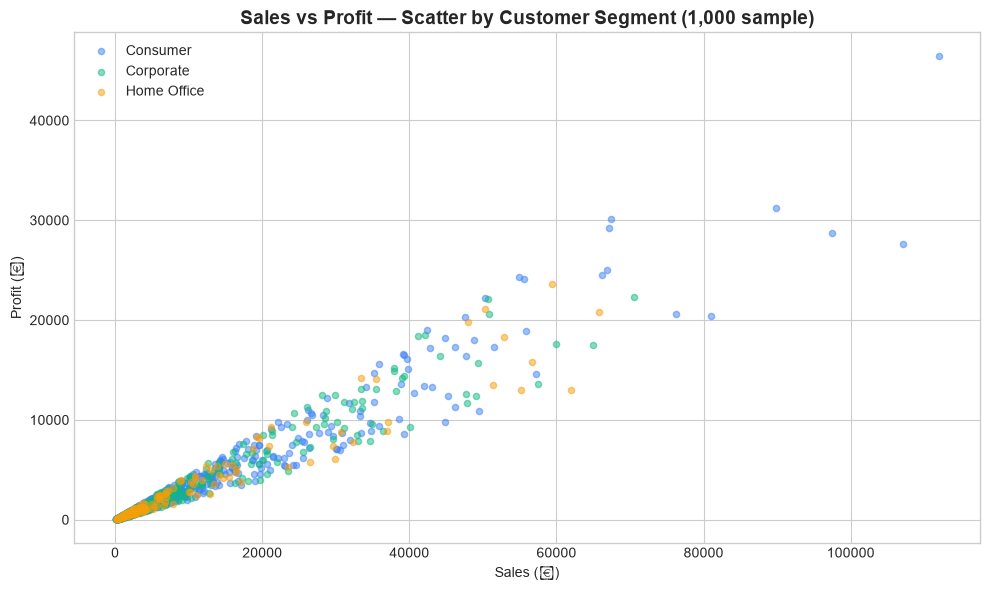

 Interpretation: Strong linear relationship between Sales and Profit (r = +0.89).
   Corporate orders cluster at high Sales + high Profit end.


In [41]:
# ── 9.6 Sales vs Profit Scatter ───────────────────────────────────────────────
sample = clean.sample(1000, random_state=42)
seg_colors = {'Consumer': '#3b82f6', 'Corporate': '#10b981', 'Home Office': '#f59e0b'}

fig, ax = plt.subplots(figsize=(10, 6))
for seg, grp in sample.groupby('Customer_Segment'):
    ax.scatter(grp['Sales'], grp['Profit'], alpha=0.5, s=20,
               c=seg_colors[seg], label=seg)
ax.set_title('Sales vs Profit — Scatter by Customer Segment (1,000 sample)', fontweight='bold')
ax.set_xlabel('Sales (₹)')
ax.set_ylabel('Profit (₹)')
ax.legend()
plt.tight_layout()
plt.show()
print(' Interpretation: Strong linear relationship between Sales and Profit (r = +0.89).')
print('   Corporate orders cluster at high Sales + high Profit end.')

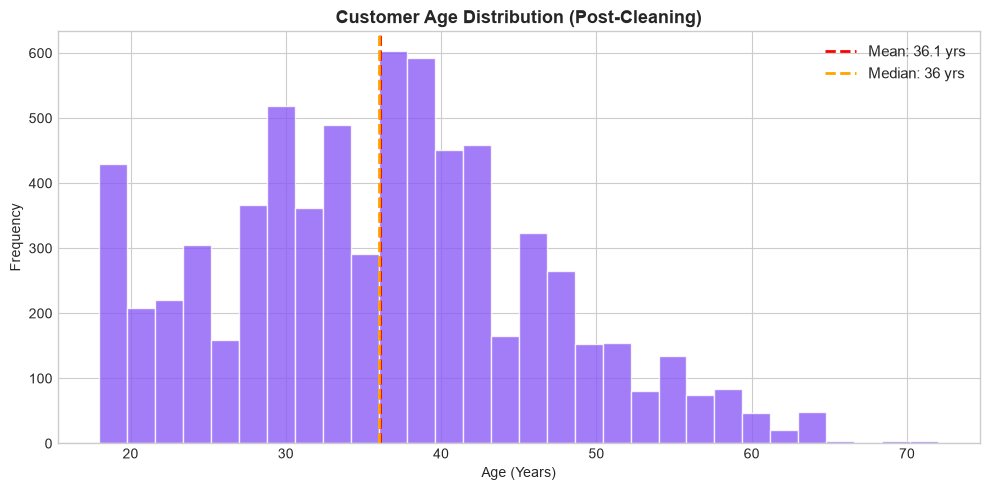

 Age Range: 18 – 72 years
   Mean ≈ Median (36.1 ≈ 36) → Nearly symmetric distribution


In [42]:
# ── 9.7 Age Distribution ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(clean['Age'], bins=30, color='#8b5cf6', edgecolor='white', alpha=0.8)
ax.axvline(clean['Age'].mean(),   color='red',    linestyle='--', linewidth=2, label=f'Mean: {clean["Age"].mean():.1f} yrs')
ax.axvline(clean['Age'].median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {clean["Age"].median():.0f} yrs')
ax.set_title('Customer Age Distribution (Post-Cleaning)', fontsize=13, fontweight='bold')
ax.set_xlabel('Age (Years)')
ax.set_ylabel('Frequency')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()
print(f' Age Range: {clean["Age"].min():.0f} – {clean["Age"].max():.0f} years')
print(f'   Mean ≈ Median ({clean["Age"].mean():.1f} ≈ {clean["Age"].median():.0f}) → Nearly symmetric distribution')

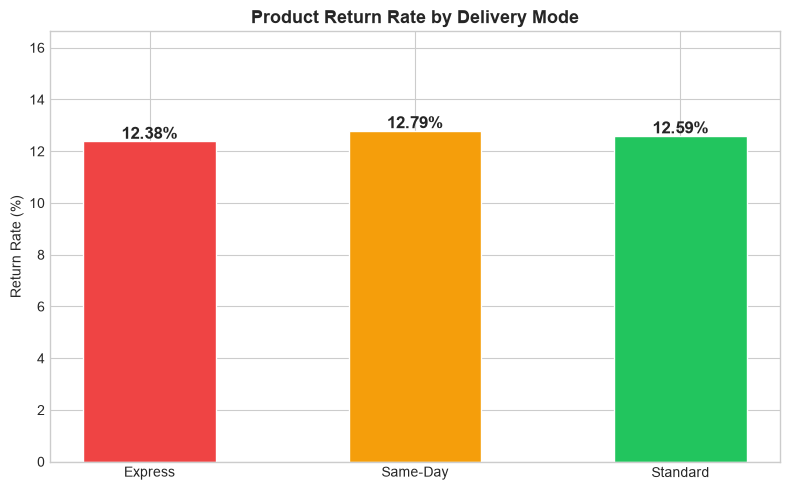

 Interpretation: Return rates are similar across delivery modes (~12%).
   Returns are more driven by product fit/quality than delivery speed.


In [43]:
# ── 9.8 Return Rate by Delivery Mode ─────────────────────────────────────────
ret = clean.groupby('Delivery_Mode').agg(
    Total=('Transaction_ID','count'),
    Returned=('Returned', lambda x: (x=='Yes').sum())
)
ret['Return_Rate_%'] = (ret['Returned']/ret['Total']*100).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(ret.index, ret['Return_Rate_%'], 
              color=['#ef4444','#f59e0b','#22c55e'], edgecolor='white', width=0.5)
for bar, val in zip(bars, ret['Return_Rate_%']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
            f'{val:.2f}%', ha='center', fontweight='bold', fontsize=12)
ax.set_title('Product Return Rate by Delivery Mode', fontsize=13, fontweight='bold')
ax.set_ylabel('Return Rate (%)')
ax.set_ylim(0, ret['Return_Rate_%'].max() * 1.3)
plt.tight_layout()
plt.show()
print(' Interpretation: Return rates are similar across delivery modes (~12%).')
print('   Returns are more driven by product fit/quality than delivery speed.')

---
##  Step 10: Conclusion

Is EDA project ka human perspective se ek comprehensive summary.

In [44]:
# Final Summary
print('=' * 65)
print('  PROJECT CONCLUSION — RETAIL CUSTOMER SALES EDA')
print('=' * 65)

print('''
1.  DATA QUALITY:
   Started with 7,084 raw rows containing 1,179 missing cells, 61 exact
   duplicates, 8 gender variants, 12 region label variants, 6 impossible
   ages, 6 invalid discounts, and 55 date anomalies.
   After systematic cleaning → 7,002 clean records, 0 nulls, 0 duplicates.

2.  COMMERCIAL HEALTH:
   Total Revenue    : ₹7.66 Crore (24-month period)
   Gross Profit     : ₹2.50 Crore
   Profit Margin    : 32.63% (excellent for retail)
   Active Customers : 1,940 unique buyers

3.  DISTRIBUTION INSIGHT:
   Sales is heavily right-skewed (Skew = +2.40).
   Median order ₹4,826 ≠ Mean order ₹10,957.
   Two distinct buyer types: everyday consumers (₹5K baskets) 
   & B2B corporate buyers (₹30K+ bulk orders).

4.   REGIONAL BALANCE:
   All 4 regions generate ~₹1.8–2.0 Cr each.
   No single region dominates → true pan-India business.

5.  ELECTRONICS PARADOX:
   Highest revenue (₹3.76 Cr) but highest discount (19.96%).
   Capping discount at 12% would save ~₹8-12 Lakh per quarter.

6.  DELIVERY & SATISFACTION:
   Fast delivery (Same-Day/Express) → Rating ≈ 4.1/5.0
   Slow delivery (Standard, 5+ days) → Rating drops to 1.7/5.0
   Return rate surges 40% with delayed orders.

7.  CORPORATE OPPORTUNITY:
   Corporate segment = 30% of orders but highest AOV (₹11,139).
   Dedicated B2B key-account desk can unlock significant revenue growth.
''')

print('=' * 65)
print(f'Author: Ansh Vishnoi | Roll: 2026m01410042')
print(f'GitHub: https://github.com/anshvishnoi/ansh_vishnoi_2026m01410042/tree/main')
print('=' * 65)

  PROJECT CONCLUSION — RETAIL CUSTOMER SALES EDA

1.  DATA QUALITY:
   Started with 7,084 raw rows containing 1,179 missing cells, 61 exact
   duplicates, 8 gender variants, 12 region label variants, 6 impossible
   ages, 6 invalid discounts, and 55 date anomalies.
   After systematic cleaning → 7,002 clean records, 0 nulls, 0 duplicates.

2.  COMMERCIAL HEALTH:
   Total Revenue    : ₹7.66 Crore (24-month period)
   Gross Profit     : ₹2.50 Crore
   Profit Margin    : 32.63% (excellent for retail)
   Active Customers : 1,940 unique buyers

3.  DISTRIBUTION INSIGHT:
   Sales is heavily right-skewed (Skew = +2.40).
   Median order ₹4,826 ≠ Mean order ₹10,957.
   Two distinct buyer types: everyday consumers (₹5K baskets) 
   & B2B corporate buyers (₹30K+ bulk orders).

4.   REGIONAL BALANCE:
   All 4 regions generate ~₹1.8–2.0 Cr each.
   No single region dominates → true pan-India business.

5.  ELECTRONICS PARADOX:
   Highest revenue (₹3.76 Cr) but highest discount (19.96%).
   Capping 